# First run: handwritten digits

Starfold sorts the rows of a numeric table into groups without being told
what the groups are. It then measures how far you can trust those groups.
This notebook runs it once on the scikit-learn digits dataset and reads
every part of the result, one cell at a time. The dataset is a copy of
the UCI handwritten digits test set: 1,797 images of 8 by 8 pixels, one
per row, with 64 pixel columns.

## What you will do

1. Load the digits dataset, one row per image and one column per pixel.
2. Run Starfold with one function call, `starfold.recover`.
3. Read the warnings it raises, the groups it found, and the settings it chose.
4. Look at a map of the groups, and at figures that show how often each group
   and each row comes back when Starfold repeats the fit on random parts of
   the table.
5. Only at the end, compare the groups with the true digits, which Starfold
   never saw.
6. Save the result to disk and load it back.

You do not need to know UMAP, HDBSCAN or Optuna beforehand. The next two
sections explain them, and every other term is explained where it first
appears. The manual covers the same run as a tutorial, in
[part 1](https://andreaswneitzel.github.io/Starfold/tutorial/digits.html) and
[part 2](https://andreaswneitzel.github.io/Starfold/tutorial/digits-refits.html).

## What you need

- A clone of the Starfold repository and Python 3.11 or 3.12. In the clone,
  run `uv sync --extra bench`. Add `--extra gpu-cu13` or `--extra gpu-cu12` if
  you have an NVIDIA GPU and want cuML (NVIDIA's GPU versions of UMAP and
  HDBSCAN). Without it, Starfold runs on the CPU.
- Jupyter. Open this notebook in Jupyter with the project's virtual
  environment (`.venv`) as the kernel.
- A few minutes. On a laptop RTX 3060 with cuML the stored run took 93.9 s,
  of which the search took 77.4 s and the refits 7.2 s. It made 314 fits (one
  fit is one run of UMAP followed by HDBSCAN) and peaked at 1,422 MB of memory.
  The CPU time is not measured. Expect several times longer, and set
  `N_JOBS = 3` (the number of CPU worker processes) to run fits in parallel.

## The one rule of this notebook

Starfold never sees which digit an image shows. The true digits stay in `y`
and appear only in cells marked **post hoc** (Latin for "after this"). Those
cells check the answer after the fact. Nothing marked post hoc influences
the groups. With your own data there will usually be no true labels, and
you stop before the post hoc cells.

## UMAP, HDBSCAN and Optuna

Starfold is built from three existing tools. This section says what each one
does; you need nothing more to follow the notebook. The manual has a page on
each: [UMAP](https://andreaswneitzel.github.io/Starfold/concepts/umap.html),
[HDBSCAN](https://andreaswneitzel.github.io/Starfold/concepts/hdbscan.html) and
[Optuna](https://andreaswneitzel.github.io/Starfold/concepts/optuna.html).

**UMAP** (McInnes, Healy and Melville 2018, arXiv:1802.03426) turns the 64
pixel columns into a few coordinates. This map is called the *embedding*, and
images that look alike sit close together in it. UMAP finds the most similar
rows of every row and arranges the map so that those links stay short. The
axes of the map have no units and no meaning. Only which rows sit near which
counts.

**HDBSCAN** (Campello, Moulavi and Sander 2013,
doi:10.1007/978-3-642-37456-2_14; McInnes and Healy 2017, arXiv:1705.07321)
then finds dense clumps in the map. Each clump is a *group*. A row that lies
between clumps belongs to no group and gets the label -1, called *noise*
(notebook 02 says "unassigned"). Noise means that no clump claimed the row. It
does not mean the measurement was bad.

**Optuna** (Akiba et al. 2019, arXiv:1907.10902) is a search library. It
proposes a *setting*, receives a score for it, and uses the scores so far to
propose the next one. Each proposal with its score is a *trial*.

A setting is one complete choice of six values. Different settings can turn
the same table into a handful of groups or into hundreds:

- `n_neighbors` (UMAP): how many similar rows each row looks at. Small values
  keep fine detail and large values the broad layout. Library default 15.
- `min_dist` (UMAP): how tightly the map packs similar rows. Default 0.1.
- `n_components` (UMAP): how many coordinates the map has. Default 2.
- `min_cluster_size` (HDBSCAN): the smallest clump that may be called a group.
  Default 5.
- `min_samples` (HDBSCAN): how smooth the density estimate is; larger values
  call more rows noise. Default 5.
- `selection_method` (HDBSCAN): `eom` keeps the most persistent clumps and
  `leaf` the finest ones. Default `eom`.

Starfold uses Optuna to choose the setting without any labels. It then
measures how reproducible the answer is. Before UMAP, it also rescales the
columns so that no column dominates because of its units. The default,
`Config(scaling="standard")`, centres each column and divides it by its
standard deviation.

## Terms used in these notebooks

You do not need to read this list now. Every term is explained again, with
the numbers, in the section that uses it. Come back here when you want to
look a word up. The manual's
[glossary](https://andreaswneitzel.github.io/Starfold/glossary.html) has the same terms.

### The table and the fits

- **row, column**: a row is one object (an image here, a star in notebook 02),
  and a column is one number measured for every object (a pixel, an abundance).
- **fit**: one run of UMAP and then HDBSCAN on some rows, which puts every row
  in a group or in noise.
- **labels, partition**: `labels` holds one integer per row, the group number
  or -1 for noise. The set of groups it defines is the *partition*. Group
  numbers are arbitrary names: two fits agree when they group rows alike, not
  when they use the same numbers.
- **seed**: a whole number that fixes every random choice, so the same seed
  gives the same run again.
- **subset**: a random 80 percent of the rows, drawn without replacement.
- **full fit**: the one fit of the chosen setting on all rows. It gives
  `labels`, the partition that Starfold reports.
- **refit**, also **world** (as in `result.worlds`): a fit of the chosen setting
  on one random subset with a new seed. Starfold makes 32. Every measure of
  reproducibility below is taken over these refits.

### Choosing the setting

- **setting, trial**: see above. `params` holds a setting.
- **Sobol design**: trials 1 to 16, placed to cover the range of every value
  evenly, without learning from any score.
- **TPE** (tree-structured Parzen estimator; Bergstra et al. 2011): Optuna's
  sampler for the later trials. It sorts earlier trials into good and poor and
  proposes new settings where the good ones sit.
- **pruning**: stopping a trial early because its first fits score below the
  median of the finished trials.
- **score**: one number per setting, computed without labels from three
  measures on subsets (prediction agreement, coverage, modularity). It is zero
  if any of the three is zero and it never reads the number of groups.
- **copy**: a version of the table with every column's values kept but shuffled
  so that no groups remain. Every value in it was measured; only which row holds
  it changes. Also called a structureless copy.
- **gap**: the score on the table minus the score on a copy. A setting that
  scores as well on structureless data gains nothing.
- **fresh re-score**: a second scoring of the best trials on new subsets and new
  copies, made because the best score of many trials is partly luck (the
  *winner's curse*).

### Reading the evidence

- **recurrence**: how often something comes back across the refits. Group
  recurrence, support and unresolved mass all measure it.
- **count interval**: the 5th to 95th percentile of the number of groups the
  refits found. It is a *stability interval*, the range over refits, and not a
  confidence interval.
- **support, own support**: for a row and a group of the full fit, how much of
  the row's refit group sits in that group, averaged over the refits that drew
  the row. Own support is the support for the row's own group.
- **unresolved**: the same average for "no group": refits that called the row
  noise, or put it in a refit group that the full fit calls noise. Unresolved
  mass is its average over all rows.
- **Jaccard overlap**: shared rows divided by rows in either of two groups; 1
  means the same rows.
- **ARI** (adjusted Rand index; Hubert and Arabie 1985,
  doi:10.1007/BF01908075): how alike two ways of grouping the same rows are, 1
  for identical and about 0 for chance. Group numbers do not matter.
- **co-association**: for a pair of rows, the share of refits that put both in
  the same group. **Contrast** is its average over pairs inside a group minus
  its average over pairs in different groups.
- **flag**: a short name for one weakness or event in a run, derived from the
  evidence arrays, for people and scripts to check.
- **strengths**: HDBSCAN's within-fit membership strength of a row. They are not
  probabilities.

### The calibration test

- **p-value**: the share of copies that score at least as high as the table,
  counting the table as one more draw. A small p means the table beats almost
  every copy. It holds only for the declared family of copies, and it is not
  the probability that the groups are real.
- **alpha**: the level at which the test is called supportive, 0.05 by default.

## Find the repository

The notebook imports a few helpers from the repository's `bench/` folder, so
it needs to know where your clone is. This cell walks up from the current
folder until it finds `pyproject.toml` and prints that folder. If it raises an
error, open the notebook from inside the clone.

In [1]:
import sys
from pathlib import Path

ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "pyproject.toml").is_file()
    ),
    None,
)
if ROOT is None:
    msg = "Run this notebook from inside a clone of the starfold repository."
    raise FileNotFoundError(msg)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(ROOT)

/home/aneitzel/projects/starfold


## Parameters

These four values are the only ones you might change.

- `RANDOM_STATE` is the seed. Every random choice of the run derives from it
  (the subsets, the copies, the refits), so the same seed repeats the run.
- `ENGINE = "auto"` uses cuML when it imports and sees a GPU. Otherwise it
  prints a warning and runs on the CPU.
- `N_JOBS` is the number of CPU worker processes.
- `FIGURES = None` writes no files. Set it to `ROOT / "docs" / "figures"` to
  rewrite the digits PNG files that the manual shows.

In [2]:
RANDOM_STATE = 0
ENGINE = "auto"
N_JOBS = 1
FIGURES = None

The next cell imports the libraries, sets small font sizes for the figures,
and defines `save_figure`, which writes a figure only when `FIGURES` is set.
It prints nothing.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import umap
from bench.beats_default import coverage_adjusted_ari
from matplotlib import ticker
from matplotlib.lines import Line2D
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler

import starfold
from starfold.result import FLAG_VOCABULARY

RUN_DIR = ROOT / "notebooks" / "runs" / "digits"
TAB10 = plt.get_cmap("tab10")
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.titlesize": 9,
        "axes.labelsize": 9,
        "legend.fontsize": 7,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
    }
)


def save_figure(fig, name):
    """Write the figure to FIGURES / name at 150 dpi; do nothing when FIGURES is None."""
    if FIGURES is None:
        return
    folder = Path(FIGURES)
    folder.mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / name, dpi=150, bbox_inches="tight")
    print(f"wrote {folder / name}")

## The data

The table comes with scikit-learn. Each row is one 8 by 8 image of a
handwritten digit, flattened to 64 pixel values from 0 (dark) to 16
(bright). `X` holds the table that Starfold sees. `y` holds the true digit of
each image and stays aside until the post hoc cells.

You should see 1797 images, 64 pixel columns and 10 classes (the digits 0
to 9).

In [4]:
X, y = load_digits(return_X_y=True)
print(f"{X.shape[0]} images, {X.shape[1]} pixel columns, values {X.min():.0f} to {X.max():.0f}")
print(f"true digits, kept aside: {np.unique(y).size} classes")

1797 images, 64 pixel columns, values 0 to 16
true digits, kept aside: 10 classes


## One call

`starfold.recover` does the whole procedure in one call:

1. It searches the settings and picks one.
2. It fits the chosen setting once on all rows. This is the *full fit*, and
   its labels are the *partition* (the split of the rows into groups) that
   Starfold reports.
3. It refits that setting on 32 random 80 percent subsets, to see which groups
   and which rows come back. Each of these is a *refit*.
4. It checks the partition against the refits with a co-association matrix (a
   table of how often each pair of rows was grouped together).
5. It raises *flags*, short warning names, wherever the evidence is weak.

`starfold.Config()` holds the budgets (up to 48 trials, 3 subsets per trial, 32
refits) and the scaling. This cell uses the defaults. The calibration test is
off by default because it costs far more than the rest of the run. It asks
whether structureless copies of the table score as high as the table, and a
later section shows how to run it.

This is the cell that takes a few minutes. When it finishes, it prints:

- which engine ran (`cuml` for the GPU, `cpu` otherwise);
- how many rows were kept. Rows with a missing or infinite value are dropped,
  never filled in, and here all 1797 are kept;
- the seconds and the number of fits for each stage, and the peak memory.

The stage names are `search` (choosing the setting), `reference` (the full fit,
plus one fit of the library defaults for comparison), `worlds` (the 32
refits), `consensus` (the co-association check) and `null` (the calibration
test, 0 here because it is off). Almost all of the time goes into the search.

In [5]:
config = starfold.Config()
print("calibration test families:", config.null_families or "none, the test is off")
result = starfold.recover(X, config=config, random_state=RANDOM_STATE, engine=ENGINE, n_jobs=N_JOBS)

prov = result.provenance
print(f"engine: asked for {prov['engine_requested']}, used {prov['engine_resolved']}")
print(f"starfold {prov['starfold_version']}, Python {prov['python']}, {prov['platform']}")
print(f"rows kept: {prov['n_kept_rows']} of {prov['n_input_rows']}, columns: {prov['n_features']}")
print("seconds per stage:", {k: round(v, 1) for k, v in prov["stage_seconds"].items()})
print("fits per stage:", prov["stage_fits"], "total", prov["total_fits"])
print(f"peak host memory: {prov['peak_rss_mb']:.0f} MB")

calibration test families: none, the test is off


engine: asked for auto, used cuml
starfold 0.2.0, Python 3.12.3, Linux-6.18.40.1-microsoft-standard-WSL2-x86_64-with-glibc2.39
rows kept: 1797 of 1797, columns: 64
seconds per stage: {'search': 77.4, 'reference': 0.5, 'worlds': 7.2, 'consensus': 0.5, 'null': 0.0, 'total': 93.9}
fits per stage: {'search': 280, 'reference': 2, 'worlds': 32, 'null': 0} total 314
peak host memory: 1422 MB


## Flags first

A flag is a short name for one weakness or event in the run. Starfold derives
it from the evidence, so a script can test for it as well as a person. Read
the flags before any number.

Starfold defines 17 flags. The cell below gives each one a plain-language
meaning in `FLAG_TEXT` and prints the ones this run raised. It stops with an
error if your Starfold version has a different list of flags. The manual's
[flags page](https://andreaswneitzel.github.io/Starfold/reference/flags.html) lists them all.

Not every flag is a fault. `null_not_run` is expected here, because the
calibration test was left off. One of the two `search_...` flags is always
raised, and it only says how the search ended.

Some meanings use terms that later sections explain (fresh re-score,
unresolved mass, co-association). Read past them now and come back once they
are defined.

In [6]:
FLAG_TEXT = {
    "search_stopped_early": "the search stopped once its best score stopped improving; "
    "this only says how the search ended",
    "search_budget_exhausted": "the search used every trial it was given; "
    "this only says how the search ended",
    "selected_is_default": "the library defaults won the fresh re-score",
    "default_within_noise": "the fresh scores of the chosen setting and the defaults differ "
    "by at most twice the standard error of their paired differences; the choice between "
    "them is not resolved",
    "no_groups_in_reference": "the fit on all rows put every row in noise",
    "high_unresolved_mass": "the unresolved mass is above 0.5: on average, most of a row's "
    "refit outcome is noise rather than its group",
    "count_unstable": "fewer than half of the refits found the same number of groups "
    "as the fit on all rows",
    "search_trial_failures": "at least one search trial raised an error; see its error field",
    "world_fit_failures": "at least one refit raised an error; see result.worlds.world_errors",
    "consensus_subsampled": "the co-association check ran on a seeded subset of rows "
    "to stay inside its memory budget",
    "consensus_disagrees": "the cut of the co-association matrix agrees with labels "
    "below 0.5; read the contrast before concluding anything",
    "null_not_run": "the calibration test did not run, so there is no p-value "
    "(expected here, see the calibration section)",
    "observed_statistic_zero": "the best score of the exploration design is zero, "
    "so there is nothing to calibrate",
    "no_structure_supported": "the calibration test ran and gave a p-value above alpha",
    "backend_disagreement": "CPU and cuML partitions agree below 0.8",
    "rows_rejected_nonfinite": "some input rows held NaN or infinity and were dropped; "
    "result.kept_rows lists the rows used",
    "n_jobs_forced_to_one_on_cuml": "n_jobs above 1 was asked for on cuML, which runs one job",
}
if set(FLAG_TEXT) != set(FLAG_VOCABULARY):
    msg = "FLAG_TEXT does not cover the flag vocabulary of this Starfold version."
    raise RuntimeError(msg)

print(f"{len(result.flags)} of {len(FLAG_VOCABULARY)} flags raised")
for flag in result.flags:
    print(f"- {flag}: {FLAG_TEXT[flag]}")

4 of 17 flags raised
- search_budget_exhausted: the search used every trial it was given; this only says how the search ended
- count_unstable: fewer than half of the refits found the same number of groups as the fit on all rows
- consensus_disagrees: the cut of the co-association matrix agrees with labels below 0.5; read the contrast before concluding anything
- null_not_run: the calibration test did not run, so there is no p-value (expected here, see the calibration section)


The stored run raised 4 of the 17 flags. Two only
describe the run: `search_budget_exhausted` (the search used all 48 trials)
and `null_not_run` (the test was off). The other two are warnings to follow
up:

- `count_unstable`: the number of groups changes a lot from refit to refit.
  The section "How many groups" shows by how much.
- `consensus_disagrees`: one of two summaries of the co-association check is
  low. The section "The co-association check" shows why it can be low while
  the groups still hold.

Neither flag says the groups are wrong. Each one tells you which evidence to
read before you rely on the groups.

## Groups, count and reproducibility

`labels` is the partition from the full fit. It holds one entry per kept row:
the group number, or -1 for noise. `result.kept_rows` maps it back to the
rows of `X`. It comes from one fit, not from a vote. To see how much it
depends on the particular rows and seeds, Starfold has fitted the same setting
again on 32 random 80 percent subsets (the refits). Three numbers summarise
what changed:

- **count interval**: the 5th to 95th percentile of the number of groups the
  refits found, rounded outward to whole numbers. It is a stability interval,
  the range over refits, and not a confidence interval. A narrow interval
  that contains the full fit's count means the count is reproducible, which
  does not make it correct.
- **unresolved mass**: how much of the table the refits fail to place in a
  group that the full fit also has. In each refit, a row counts 1 if it lands
  in noise, and otherwise the share of its refit group that the full fit calls
  noise. This is averaged over the refits that drew the row, then over rows. 0
  means every refit agrees with the full fit, and above 0.5 the groups describe
  a minority of the rows.
- **group recurrence**: for each group, how often it comes back. In every
  refit, the group is matched with the refit group that overlaps it most, and
  the overlap is the Jaccard index (rows in both, divided by rows in either).
  Recurrence is the mean of that overlap over refits, and 1 means the group
  comes back with exactly the same members each time. The band beside it is
  the 5th to 95th percentile over refits.

The cell prints the number of groups and noise rows in the full fit, the count
interval, the unresolved mass, and one line per group with its size,
recurrence and band.

In [7]:
w = result.worlds
labels = result.labels
sizes = np.bincount(labels[labels >= 0], minlength=result.n_groups)
print(f"groups in the fit on all rows: {result.n_groups}")
print(f"noise rows: {(labels < 0).sum()} of {labels.size}")
print(
    f"refits: {w.count_values.size}; groups found: {w.count_interval[0]} to {w.count_interval[1]}"
)
print(f"unresolved mass: {result.unresolved_mass:.3f}")
print("group recurrence, with its 5 to 95 percent band over refits:")
for group, (recurrence, (low, high), size) in enumerate(
    zip(w.group_recurrence, w.group_recurrence_band, sizes, strict=True)
):
    print(
        f"  group {group:2d}: {size:4d} rows, recurrence {recurrence:.2f} ({low:.2f} to {high:.2f})"
    )

groups in the fit on all rows: 10
noise rows: 30 of 1797
refits: 32; groups found: 3 to 16
unresolved mass: 0.044
group recurrence, with its 5 to 95 percent band over refits:
  group  0:  178 rows, recurrence 1.00 (1.00 to 1.00)
  group  1:  182 rows, recurrence 1.00 (0.99 to 1.00)
  group  2:  172 rows, recurrence 0.84 (0.12 to 0.99)
  group  3:  324 rows, recurrence 0.54 (0.25 to 0.81)
  group  4:   62 rows, recurrence 0.82 (0.05 to 0.98)
  group  5:   19 rows, recurrence 0.45 (0.02 to 0.94)
  group  6:  193 rows, recurrence 0.77 (0.15 to 1.00)
  group  7:  288 rows, recurrence 0.73 (0.22 to 0.97)
  group  8:  165 rows, recurrence 0.73 (0.13 to 0.99)
  group  9:  184 rows, recurrence 0.70 (0.14 to 0.99)


In the stored run the full fit found 10 groups and
called 30 of 1797 rows noise. Three things stand out:

- The refits found anywhere from 3 to 16 groups. That wide interval is why
  `count_unstable` was raised. Treat the count of 10 as one fit's answer,
  not as a finding.
- The unresolved mass is 0.044, so the refits place almost every row in a
  group that the full fit also has.
- Recurrence varies by group. Groups 0 and 1 come back with the same members
  every time (1.00). Group 3 (324 rows) and group 5 (19 rows) sit near 0.5,
  and their wide bands say they often split or merge in a refit.

Use recurrence to decide which groups to lean on and which to report with
caution. A group that recurs is reproducible, which still does not make it a
true population.

## The settings

This cell prints the six values of three settings side by side. Each column
is one setting:

- `params` (chosen) is the setting the search picked. It was tested on 80 percent
  subsets.
- `deployed_params` produced `labels`. `min_cluster_size` and `min_samples`
  count rows, and a group that holds 5 of 80 rows holds 6.25 of 100, so both are
  multiplied by the ratio of the rows in the full fit to the rows in a subset.
  The other four values do not change.
- `default_params` are the umap-learn and hdbscan defaults, fitted once on all
  rows as the comparison (`default_labels`).

In the stored output below, the search moved away from the defaults: 4 map dimensions
instead of 2, and larger `min_cluster_size` and `min_samples`. The deployed
column shows the two row counts scaled up from 11 and 9 to 14 and 11.

In [8]:
def as_text(value):
    return f"{value:.3f}" if isinstance(value, float) else str(value)


columns = {
    "chosen": result.params,
    "deployed": result.deployed_params,
    "defaults": result.default_params,
}
print(f"{'setting':<20}" + "".join(f"{name:>12}" for name in columns))
for name in result.params.to_dict():
    row = "".join(f"{as_text(p.to_dict()[name]):>12}" for p in columns.values())
    print(f"{name:<20}{row}")

setting                   chosen    deployed    defaults
n_neighbors                   13          13          15
min_dist                   0.262       0.262       0.100
n_components                   4           4           2
min_cluster_size              11          14           5
min_samples                    9          11           5
selection_method             eom         eom         eom


## How the setting was chosen

This section is the longest in the notebook. It explains how one setting won
out of 48. You can skim it on a first pass and come back later. The manual
covers the same ground on its
[score page](https://andreaswneitzel.github.io/Starfold/metrics/score.html) and its
[copies page](https://andreaswneitzel.github.io/Starfold/concepts/copies-and-gaps.html).

Optuna runs up to 48 trials, each one a setting:

- trial 0 is the library defaults, so Starfold always weighs the answer that
  the tools would give without a search;
- trials 1 to 16 are a Sobol design, which places settings to cover the range
  of every value evenly and uses no score;
- later trials come from TPE (tree-structured Parzen estimator), which learns
  from the earlier scores and proposes settings where the good ones sit.

Every trial is fitted on the same 3 subsets, so that a difference
in score comes from the settings and not from which rows were drawn. Three
measures come from those fits:

- *prediction agreement*: a fit on one subset predicts a group for each row it
  never saw, from that row's nearest neighbours among the rows it did see. The
  prediction is compared with the fit on another subset that did see the row,
  using the ARI (adjusted Rand index: 1 for the same grouping, about 0 for
  chance). A setting that tears a smooth region into small clumps cannot
  predict unseen rows.
- *coverage*: the share of those rows that both fits assign to a group, so that
  calling most rows noise does not pay.
- *modularity* (Newman 2006, doi:10.1073/pnas.0601602103): every row is linked
  to its 15 nearest rows in the table's own scaled columns, before any map is
  drawn, and modularity is the share of links that stay inside groups beyond
  what chance would give. It gives no credit for a separation that UMAP
  invents.

The score is the cube root of their product, so a zero in any one of them makes
it zero. It never reads the number of groups.

Some settings score well on any table: cut into
compact pieces, a smooth cloud gives pieces that come back and look tidy. To
discount this, the same setting is also scored on a structureless copy of the
table, on the same subsets. The copy keeps every column's values exactly and the
overall correlation between columns, and reorders which values sit together, so
the rows form one smooth elliptical cloud with no groups (a Gaussian copula,
explained in notebook 03). The trial score is the excess over the copy, called
the gap (Tibshirani, Walther and Hastie 2001,
doi:10.1111/1467-9868.00293).

From trial 17, a trial is pruned, meaning stopped
early, if its score after two of its three fits is below the median of the
finished trials. Up to 3 pruned trials that were ahead of the best finished
trial are completed at the end ("completed after pruning"). From trial 33, the
search stops once the best score has improved by less than 0.01 over 16 trials.

The best of many noisy scores is partly luck, and so
too high (the winner's curse). The top 3 finished trials and the defaults are
therefore scored again on new subsets and new copies, which they were not
chosen on, and the largest fresh gap wins, with ties going to the defaults.
This is why the winner need not be the trial with the highest gap during the
search. The table of these candidates is the sensitivity report: close
runners-up mean that the choice among them is not sharp.

The cell first prints how many trials ran and how they ended. Then it prints
a table of the candidates of the fresh re-score, the chosen one first:

- `search gap`: the trial's gap during the search;
- `fresh score` and `fresh gap`: the score and the gap from the re-score;
- the last column: how many groups each of the 3 fresh fits found.

The last lines compare the chosen setting with the defaults on the fresh
scores, once per ordered pair of subsets (six pairs). `beats the defaults
under the objective` only says that the chosen fresh gap is larger than the
defaults'. Whether the difference exceeds the noise is the flag
`default_within_noise` (raised when the difference is within 2 standard
errors of the six paired differences).

In [9]:
s = result.search
print(f"trials run: {len(s.trials)} of {config.n_trials}; stop reason: {s.stop_reason}")
print(
    f"complete {s.n_completed}, pruned {s.n_pruned}, "
    f"completed after pruning {s.n_completed_after_prune}"
)
print(
    f"search fits: {s.n_fits}; best score of trial 0 and the Sobol design: {s.exploration_max:.3f}"
)
print()
print(f"{'trial':>6}{'search gap':>12}{'fresh score':>13}{'fresh gap':>11}  groups per fresh fit")
for rank, candidate in enumerate(s.candidates):
    tags = ["chosen"] if rank == 0 else []
    tags += ["defaults"] if candidate.trial_number == 0 else []
    print(
        f"{candidate.trial_number:>6}{candidate.score:>12.3f}{candidate.fresh_score:>13.3f}"
        f"{candidate.gap:>11.3f}  {list(candidate.fit_counts)} {', '.join(tags)}"
    )
print()
print(f"fresh score: chosen {s.score_selected:.3f}, defaults {s.score_default:.3f}")
print(f"fresh gap: chosen {s.gap_selected:.3f}, defaults {s.gap_default:.3f}")
print("chosen minus defaults per subset pair:", [round(d, 3) for d in s.paired_differences])
print(f"beats the defaults under the objective: {s.beats_default_under_objective}")
print(f"chosen setting is the defaults: {s.selected_is_default}")

trials run: 48 of 48; stop reason: budget
complete 34, pruned 14, completed after pruning 3
search fits: 280; best score of trial 0 and the Sobol design: 0.710

 trial  search gap  fresh score  fresh gap  groups per fresh fit
    33       0.730        0.828      0.661  [12, 11, 15] chosen
     0       0.539        0.789      0.565  [40, 33, 41] defaults
     7       0.710        0.625      0.455  [3, 9, 8] 
    37       0.797        0.602      0.414  [3, 9, 9] 

fresh score: chosen 0.828, defaults 0.789
fresh gap: chosen 0.661, defaults 0.565
chosen minus defaults per subset pair: [0.087, 0.032, 0.075, 0.004, 0.045, -0.016]
beats the defaults under the objective: True
chosen setting is the defaults: False


In the stored run all 48 trials ran and 14 were
pruned. Trial 33 was chosen with a fresh gap of 0.661, against 0.565 for the
defaults. Trial 37 had the highest gap during the search (0.797) but only
0.414 when re-scored: the winner's curse at work, and the reason for the
re-score. Five of the six paired differences favour the chosen setting, and
`default_within_noise` was not raised, so the choice over the defaults is
clear under this objective.

The last column shows something the score never looked at: the defaults'
fresh fits found 33 to 41 groups, the chosen setting's 11 to 15. The score
rewards groups that come back and ignores how many there are.

## A picture of the groups

HDBSCAN found the groups in the UMAP coordinates of the deployed setting, which
can have up to 10 dimensions (the figure title gives the number). A screen has
two. So this cell runs one more UMAP, on the CPU, on the standardised pixels
(each pixel rescaled to mean 0 and variance 1). It uses the same `n_neighbors`
and `min_dist` but two dimensions. This is a display refit only: the axes have
no units, and its distances are not the ones HDBSCAN saw. Neighbours on the map
are usually neighbours in the table. Do not over-read the gaps between islands
or their sizes.

Each point is one image, drawn at the same place in all three panels:

- left panel (post hoc): coloured by the true digits, which Starfold never
  used;
- middle panel: Starfold's groups. The opacity of each point is its *own
  support*, a 0-to-1 measure of how reliably the row comes back with its group
  (defined under "Support per row"). It is floored at 0.1 so every row stays
  visible. Faint points are rows that did not come back reliably;
- right panel: one fit of the library defaults with one seed, for comparison.

Grey points are noise, the rows HDBSCAN assigns to no group.

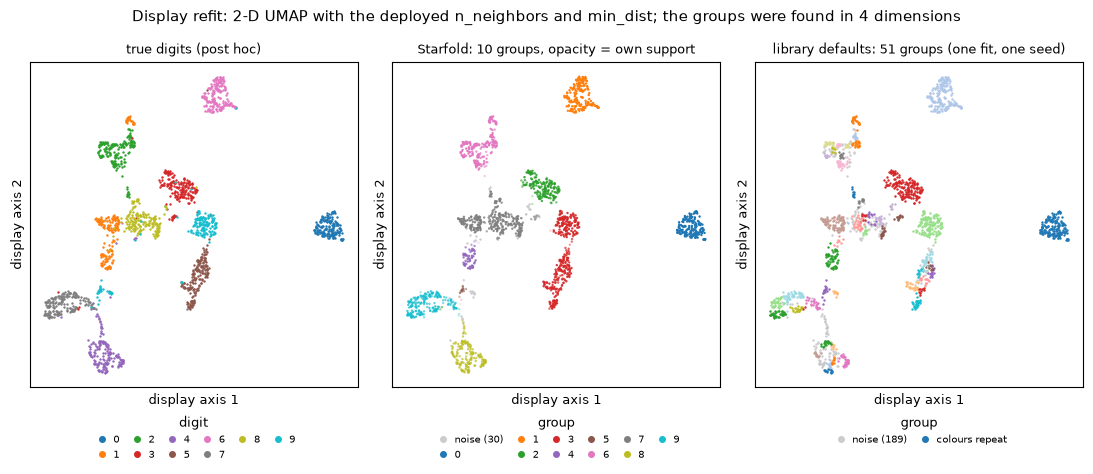

In [10]:
x = X[result.kept_rows]
truth = y[result.kept_rows]
layout = umap.UMAP(
    n_neighbors=result.deployed_params.n_neighbors,
    min_dist=result.deployed_params.min_dist,
    n_components=2,
    random_state=0,
    n_jobs=1,
).fit_transform(StandardScaler().fit_transform(x))


def group_colours(n):
    cmap = plt.get_cmap("tab10" if n <= 10 else "tab20")
    return [cmap(i % cmap.N) for i in range(n)]


def draw_partition(ax, partition, title, *, legend_title, opacity=None):
    """Scatter the display layout coloured by a partition, noise in grey."""
    noise = partition < 0
    ax.scatter(*layout[noise].T, s=3, color="0.8", lw=0)
    groups = np.unique(partition[~noise])
    colours = group_colours(groups.size)
    for colour, group in zip(colours, groups, strict=True):
        members = partition == group
        alpha = 1.0 if opacity is None else np.clip(np.nan_to_num(opacity[members]), 0.1, 1.0)
        ax.scatter(*layout[members].T, s=3, color=colour, alpha=alpha, lw=0)
    handles = (
        [Line2D([], [], ls="", marker="o", ms=4, color="0.8", label=f"noise ({noise.sum()})")]
        if noise.any()
        else []
    )
    if groups.size <= 20:
        handles += [
            Line2D([], [], ls="", marker="o", ms=4, color=c, label=str(g))
            for c, g in zip(colours, groups, strict=True)
        ]
    else:
        handles.append(
            Line2D([], [], ls="", marker="o", ms=4, color=colours[0], label="colours repeat")
        )
    ax.legend(
        handles=handles,
        title=legend_title,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.06),
        ncol=6,
        frameon=False,
        handletextpad=0.2,
        columnspacing=0.8,
    )
    ax.set_title(title)
    ax.set_xlabel("display axis 1")
    ax.set_ylabel("display axis 2")
    ax.set_xticks([])
    ax.set_yticks([])


n_default = np.unique(result.default_labels[result.default_labels >= 0]).size
fig, axes = plt.subplots(1, 3, figsize=(11, 4.8))
draw_partition(axes[0], truth, "true digits (post hoc)", legend_title="digit")
draw_partition(
    axes[1],
    labels,
    f"Starfold: {result.n_groups} groups, opacity = own support",
    legend_title="group",
    opacity=w.own_support,
)
draw_partition(
    axes[2],
    result.default_labels,
    f"library defaults: {n_default} groups (one fit, one seed)",
    legend_title="group",
)
fig.suptitle(
    "Display refit: 2-D UMAP with the deployed n_neighbors and min_dist; "
    f"the groups were found in {result.deployed_params.n_components} dimensions"
)
fig.tight_layout()
save_figure(fig, "digits_partitions.png")
plt.show()

Compare the middle panel with the left one: where a
Starfold group covers one digit's island, the group matches a digit. Then
compare the middle with the right: the defaults cut the same islands into
many more small groups. Faint regions in the middle panel mark where the
grouping is fragile.

## Settings against groups

Each point is one complete trial of the search (a trial that ran all its fits),
with its score on the horizontal axis (the gap over the copy, as defined above)
and the number of groups its fits found on the vertical axis (the median over
the trial's fits, on a logarithmic scale). The colour says how the trial was
proposed: by the Sobol design, by TPE, or as one of the pruned trials completed
at the end. The star is the library defaults (trial 0) and the ring is the
trial that was chosen after the fresh re-score.

No new fit runs here: everything comes from `result.search.trials`. Pruned
trials stopped after two fits and have no gap, so they are left out. The score
never reads the group count, so nothing pulls the points toward a particular
height, and the dotted line at the true number of digits is post hoc. A
trial that finds no group at all cannot be drawn on a log axis and is counted
in the title.

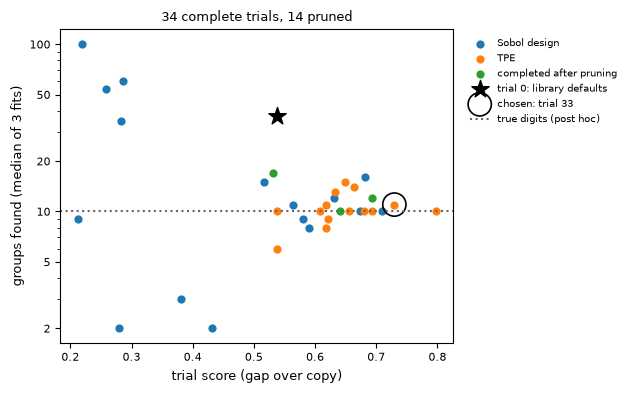

In [11]:
complete = [t for t in s.trials if t.state == "complete"]
score = np.array([t.score for t in complete])
found = np.array([np.median(t.fit_counts) for t in complete])
phase = np.array([t.phase for t in complete])
number = np.array([t.number for t in complete])
shown = found > 0
chosen = s.candidates[0].trial_number

fig, ax = plt.subplots(figsize=(6.4, 4))
for i, (key, name) in enumerate(
    (
        ("exploration", "Sobol design"),
        ("convergence", "TPE"),
        ("completion", "completed after pruning"),
    )
):
    mask = shown & (phase == key)
    if mask.any():
        ax.scatter(score[mask], found[mask], s=24, color=TAB10(i), label=name)
mask = shown & (number == 0)
if mask.any():
    ax.scatter(
        score[mask], found[mask], marker="*", s=170, color="k", label="trial 0: library defaults"
    )
mask = shown & (number == chosen)
if mask.any():
    ax.scatter(
        score[mask],
        found[mask],
        s=280,
        facecolors="none",
        edgecolors="k",
        lw=1.2,
        label=f"chosen: trial {chosen}",
    )
ax.axhline(np.unique(y).size, ls=":", color="0.4", label="true digits (post hoc)")
ax.set_yscale("log")
ax.yaxis.set_major_locator(ticker.LogLocator(subs=(1.0, 2.0, 5.0)))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(ticker.NullFormatter())
ax.set_xlabel("trial score (gap over copy)")
ax.set_ylabel(f"groups found (median of {config.n_resamples} fits)")
hidden = f"; {(~shown).sum()} with no group not shown" if (~shown).any() else ""
ax.set_title(f"{shown.sum()} complete trials, {s.n_pruned} pruned{hidden}")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
fig.tight_layout()
save_figure(fig, "digits_settings_vs_groups.png")
plt.show()

In the stored run the low-scoring trials found anything from a few groups to
dozens. The
high-scoring trials sit in a narrower band of counts, and the defaults (the
star) score lower than most TPE trials. The score never saw the count, so the
narrowing is a side effect of rewarding reproducible groups. It is still not
evidence for any particular number of groups.

## Support per row

The previous sections asked how whole groups behave. This one asks the same
of each row. The manual defines it on its
[support page](https://andreaswneitzel.github.io/Starfold/metrics/support.html).

The 32 refits each fit a random 80 percent of the rows. Take a row and a refit
that drew it. Either the refit called the row noise, or it put the row in a
refit group. That refit group is made of rows that the full fit split among
its own groups (or called noise).

- *Support* of the row for a group of the full fit is the average, over the
  refits that drew the row, of the share of the row's refit group that sits in
  that full-fit group. *Own support*, from 0 to 1, is the support for the row's
  own group. High means the row keeps company with the same rows every time.
- The *unresolved share* is the same average for the outcome "no group": a
  refit that called the row noise counts 1, and otherwise the share of its refit
  group that the full fit calls noise. Support summed over groups plus the
  unresolved share is 1 on every row a refit drew.

The cell draws three histograms (bar charts of how many rows fall in each
range of values):

- left: own support of every grouped row. Mass piled near 1 is good;
- middle: the unresolved share of every row, with its mean (the unresolved
  mass) as a dashed line. Mass piled near 0 is good;
- right (post hoc): the left histogram again, with each bar split by whether
  the row's true digit is the majority digit of its group.

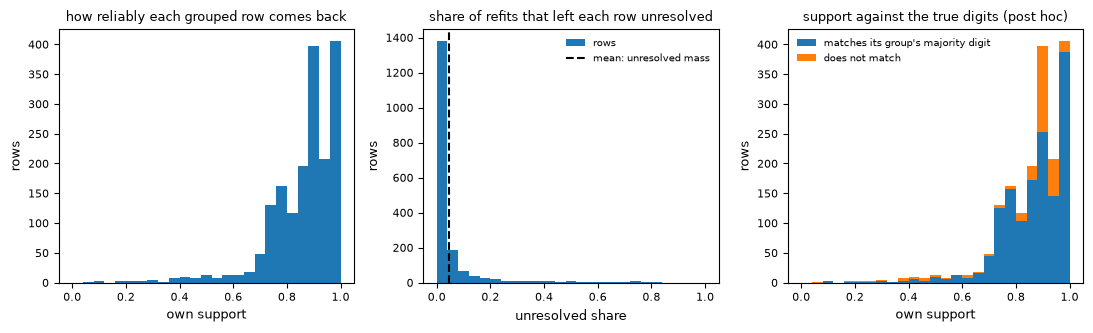

In [12]:
def majority_digit(partition):
    """Post hoc: each group's majority true digit and that digit's share of the group."""
    groups = np.unique(partition[partition >= 0])
    counts = [np.bincount(truth[partition == g], minlength=10) for g in groups]
    return (
        groups,
        np.array([c.argmax() for c in counts]),
        np.array([c.max() / c.sum() for c in counts]),
    )


own = w.own_support
grouped = labels >= 0
groups, digit, share = majority_digit(labels)
matches = np.zeros(labels.size, dtype=bool)
matches[grouped] = truth[grouped] == digit[np.searchsorted(groups, labels[grouped])]
scored = grouped & np.isfinite(own)
bins = np.linspace(0.0, 1.0, 26)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].hist(own[scored], bins=bins, color=TAB10(0))
axes[0].set_xlabel("own support")
axes[0].set_ylabel("rows")
axes[0].set_title("how reliably each grouped row comes back")
unresolved = w.unresolved[np.isfinite(w.unresolved)]
axes[1].hist(unresolved, bins=bins, color=TAB10(0), label="rows")
axes[1].axvline(result.unresolved_mass, color="k", ls="--", label="mean: unresolved mass")
axes[1].set_xlabel("unresolved share")
axes[1].set_ylabel("rows")
axes[1].set_title("share of refits that left each row unresolved")
axes[1].legend(frameon=False)
axes[2].hist(
    [own[scored & matches], own[scored & ~matches]],
    bins=bins,
    stacked=True,
    color=[TAB10(0), TAB10(1)],
    label=["matches its group's majority digit", "does not match"],
)
axes[2].set_xlabel("own support")
axes[2].set_ylabel("rows")
axes[2].set_title("support against the true digits (post hoc)")
axes[2].legend(frameon=False, loc="upper left")
fig.tight_layout()
save_figure(fig, "digits_support.png")
plt.show()

In the stored run most grouped rows have own support near
1, and most rows have an unresolved share near 0. The right panel shows that
rows which do not match their group's digit also reach high support. High
support means a row keeps the same company, not that the company is right.
Keeping only high-support rows gains some purity at the cost of completeness.

## Recurrence per group

This figure draws the recurrence numbers printed earlier, which the manual's
[recurrence page](https://andreaswneitzel.github.io/Starfold/metrics/recurrence.html)
defines.

For each group of the full fit, every refit is searched for the group that
overlaps it best. The overlap is the Jaccard index: rows in both groups divided
by rows in either, 1 for identical sets and 0 for disjoint ones. The group's
*recurrence* is the mean of that best overlap over the refits.

The [help page](https://rdrr.io/cran/fpc/man/clusterboot.html) of the R function
`clusterboot` (Hennig, R package fpc) reads a mean Jaccard of 0.85
or more as highly stable. It says a Jaccard of 0.5 or less in one resample
means the cluster dissolved. Here these lines are marks to read against, not
filters. A group below 0.5 is not removed.

- Left: recurrence of each group, with the 5 to 95 percent band over refits.
- Middle: the size of each group in the full fit, in rows.
- Right (post hoc): recurrence against purity, the share of the group that has
  its majority digit. It asks whether groups that recur are also pure.

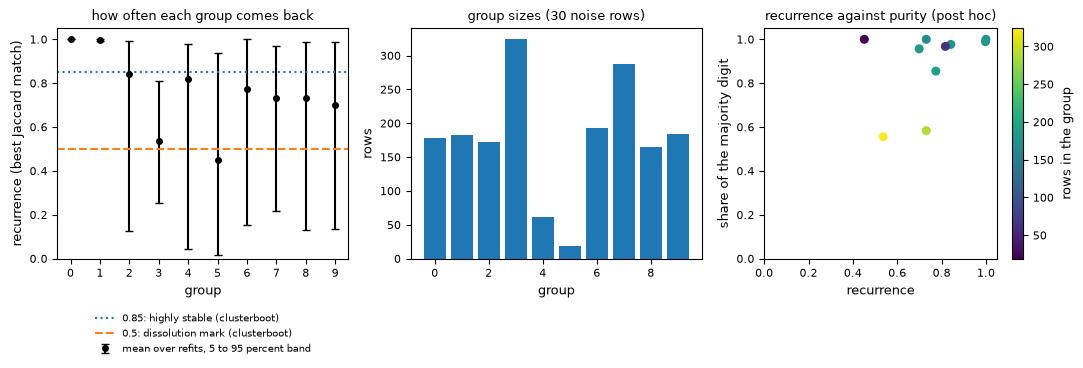

In [13]:
index = np.arange(w.group_recurrence.size)
lower = np.clip(w.group_recurrence - w.group_recurrence_band[:, 0], 0.0, None)
upper = np.clip(w.group_recurrence_band[:, 1] - w.group_recurrence, 0.0, None)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
axes[0].errorbar(
    index,
    w.group_recurrence,
    yerr=[lower, upper],
    fmt="o",
    ms=4,
    capsize=3,
    color="k",
    label="mean over refits, 5 to 95 percent band",
)
axes[0].axhline(0.85, ls=":", color=TAB10(0), label="0.85: highly stable (clusterboot)")
axes[0].axhline(0.5, ls="--", color=TAB10(1), label="0.5: dissolution mark (clusterboot)")
axes[0].set_ylim(0.0, 1.05)
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[0].set_xlabel("group")
axes[0].set_ylabel("recurrence (best Jaccard match)")
axes[0].set_title("how often each group comes back")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
axes[1].bar(index, sizes, color=TAB10(0))
axes[1].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[1].set_xlabel("group")
axes[1].set_ylabel("rows")
axes[1].set_title(f"group sizes ({(labels < 0).sum()} noise rows)")
points = axes[2].scatter(w.group_recurrence, share, c=sizes, cmap="viridis", s=30)
fig.colorbar(points, ax=axes[2], label="rows in the group")
axes[2].set_xlim(0.0, 1.05)
axes[2].set_ylim(0.0, 1.05)
axes[2].set_xlabel("recurrence")
axes[2].set_ylabel("share of the majority digit")
axes[2].set_title("recurrence against purity (post hoc)")
fig.tight_layout()
save_figure(fig, "digits_groups.png")
plt.show()

In the stored run groups 0 and 1 sit at the top, above
the 0.85 line, with almost no band. Group 5 falls below 0.5, which matches the
clusterboot dissolution mark, and group 3 sits slightly above it. Most other
groups have a mean between the two lines but a band that reaches far down:
they usually come back, but some refits split or merge them. The right panel
shows that the two largest groups (3 and 7) are also the least pure. A group
can recur without being pure, and a stable partition is not thereby a true one.

## How many groups

The figure shows the number of groups each of the 32 refits found. Each bar is
the share of refits at one count, and the shaded band is the count interval,
defined on the manual's
[count-interval page](https://andreaswneitzel.github.io/Starfold/metrics/count-interval.html).

The interval is the 5th to the 95th percentile of those counts, rounded
outward. It is a stability interval: the range the count takes when the rows
are resampled (and, where a table has measurement errors, redrawn). It is not
a confidence interval for a true number of groups. A narrow interval that
holds the count of the full fit means the count is reproducible under
resampling. It does not mean the count is true. The number of arbitrary,
overlapping populations cannot be pinned down without a declared target
quantity and assumptions.

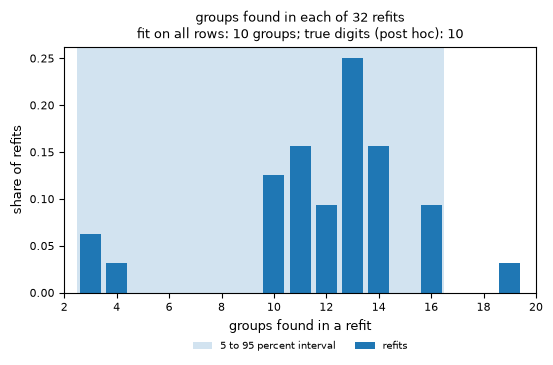

In [14]:
values, freq = np.unique(w.count_values, return_counts=True)
low, high = w.count_interval
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.axvspan(low - 0.5, high + 0.5, color=TAB10(0), alpha=0.2, lw=0, label="5 to 95 percent interval")
ax.bar(values, freq / w.count_values.size, width=0.8, color=TAB10(0), label="refits")
ax.set_xlim(min(values.min(), low) - 1, max(values.max(), high) + 1)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.set_xlabel("groups found in a refit")
ax.set_ylabel("share of refits")
ax.set_title(
    f"groups found in each of {w.count_values.size} refits\n"
    f"fit on all rows: {result.n_groups} groups; true digits (post hoc): {np.unique(y).size}"
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
fig.tight_layout()
save_figure(fig, "digits_counts.png")
plt.show()

In the stored run the interval runs from 3 to 16. Most
refits found 10 to 16 groups. A few found only 3 or 4, and one found 19.
This spread is what raised `count_unstable`. Report the interval with the
count, and do not treat the count of 10 as a result.

## What else the refits recorded

The cell below prints the rest of what the refits stored beside the labels.
You will rarely need all of it, but each line is a check you can cite.

- `refit fits`, `failures`: how many refits ran and how many raised an error
  (a failed refit is recorded, not hidden).
- `refits that drew each row`: with 80 percent subsets, each row is drawn by
  about 26 of the 32 refits, and this line gives the smallest and largest count.
- `support`: the matrix defined under "Support per row", one row per table row
  and one column per group. With `unresolved`, each drawn row sums to 1, which
  the printed identity checks.
- `agreement of each refit with labels`: for every refit, the ARI between its
  groups and `labels` on the rows both assign, times the share of rows both
  assign. Both parts lower the number, so it is 1 only for the same partition.
- `property_median` and `property_band`: for each group and column, the median
  value over refits and its 5 to 95 percent band, in the original units of the
  column. "Measurement draws" says whether the refits also redrew each value
  from an error (`X_err`); here there is none, so the band comes from
  resampling alone.
- `strengths`: HDBSCAN's within-fit membership strength of a row, from 0 to 1,
  1 at the core of a group. It describes one fit and is not a probability.
- `backend comparison`: "not run" unless `Config(check_backends=True)`, which fits
  the chosen setting on the CPU and the GPU engine and compares the partitions
  (never the label numbers, which differ between engines).

In the stored run no refit failed, each row was drawn by 16 to 31 refits,
and the identity holds. The median agreement of a refit with `labels` is
0.79, with a range from 0.13 to 0.89: most refits resemble the full fit, and
a few differ a lot.

In [15]:
sampled = w.n_sampled > 0
total = result.support[sampled].sum(axis=1) + w.unresolved[sampled]
failures = sum(bool(error) for error in w.world_errors)
print(f"refit fits: {w.n_fits}, failures: {failures}, seconds: {w.seconds:.1f}")
print(f"refits that drew each row: {w.n_sampled.min()} to {w.n_sampled.max()}")
print(
    f"support: shape {result.support.shape}; support + unresolved = 1 on drawn rows: "
    f"{np.allclose(total, 1.0, atol=1e-4)}"
)
agreement = w.world_agreement
print(
    f"agreement of each refit with labels (ARI times coverage): median "
    f"{np.median(agreement):.2f}, {agreement.min():.2f} to {agreement.max():.2f}"
)
print(
    f"property_median: shape {w.property_median.shape} (group by column); "
    f"measurement draws: {w.property_propagated}"
)
width = w.property_band[..., 1] - w.property_band[..., 0]
print(f"median width of the property bands: {np.nanmedian(width):.2f} pixel units")
print(f"strengths of grouped rows: median {np.median(result.strengths[grouped]):.2f}")
print("backend comparison:", "not run" if result.backends is None else result.backends)

refit fits: 32, failures: 0, seconds: 7.2
refits that drew each row: 16 to 31
support: shape (1797, 10); support + unresolved = 1 on drawn rows: True
agreement of each refit with labels (ARI times coverage): median 0.79, 0.13 to 0.89
property_median: shape (10, 64) (group by column); measurement draws: False
median width of the property bands: 1.00 pixel units
strengths of grouped rows: median 1.00
backend comparison: not run


## The co-association check

The check asks whether the grouping is a property of the rows or of one fit's
label numbers. The manual's
[co-association page](https://andreaswneitzel.github.io/Starfold/metrics/coassociation.html)
describes it.

For every pair of rows, the check counts the share of refits that put the two
in the same group, among the refits that assigned both. That share is the
*co-association* of the pair. It needs no matching of label numbers between
refits, since only "same group or not" is used.

- *within* and *between*: the mean co-association over pairs of rows in the same
  group of `labels`, and over pairs in different groups. If the groups hold,
  the first is high and the second low. Their difference is the *contrast*.
- *agreement of the cut*: HDBSCAN is run once more, on the co-association
  turned into a distance (1 minus the share), and its groups are compared with
  `labels` by ARI times the share of rows both assign. Above 5,792 rows the
  check keeps a subset of 4,096 rows, because the pair matrix grows with the
  square of the rows, and prints `subset: True`.

The cut can fail on matrices with many ties, so `consensus_disagrees` (agreement
below 0.5) can be raised even when the contrast is high. Read the two together.

In [16]:
c = result.consensus
print(f"rows used: {c.n_rows} (subset: {c.subsampled}), memory: {c.bytes_used / 2**20:.0f} MiB")
print(f"within-group co-association:  {c.within_association:.3f}")
print(f"between-group co-association: {c.between_association:.3f}")
print(f"contrast:                     {c.contrast:.3f}")
print(f"agreement of the cut with labels (ARI times coverage): {c.agreement:.3f}")
print(f"groups in the cut: {np.unique(c.labels[c.labels >= 0]).size}")

rows used: 1797 (subset: False), memory: 49 MiB
within-group co-association:  0.820
between-group co-association: 0.068
contrast:                     0.751
agreement of the cut with labels (ARI times coverage): 0.135
groups in the cut: 3


In the stored run pairs inside a group are grouped
together in 0.820 of the refits, pairs across groups in 0.068, a contrast of
0.751. That is a clear separation. The cut, however, found only 3 groups and
agrees with `labels` at 0.135, which raised `consensus_disagrees`. So the
pairs say the groups hold on average, while one automatic cut of the same
matrix merges them into a few large groups. Neither number settles it alone.
The per-group recurrence above tells you which groups the merging touches.

## The calibration test

This test did not run here. `result.null.skipped_reason` is `null_not_run`,
and `result.null.p_value` holds a placeholder of 1.0, not a result. The
manual's [p-value page](https://andreaswneitzel.github.io/Starfold/metrics/calibration-p.html)
describes the test.

The test asks whether the search would have found something as good in data
with no groups. It makes a structureless copy of the table (see "Terms used in
these notebooks") and runs the opening of the search on it: trial 0 and the
16 Sobol trials, 17 settings in all. A gap needs a score on the data and a
score on its own structureless copy. On a copy, that means 3 fits on the copy
and 3 on a copy of the copy: 6 fits per setting, 102 fits per copy.

The best gap that any of the 17 settings reaches on the copy is recorded. This
is repeated for up to 19 copies, and it stops early once 3 copies have reached
the table's own value. That value is `exploration_max`, the best gap of the
same 17 settings on the real table. The search summary above printed it as
`best score of trial 0 and the Sobol design`.

The p-value is (h + 1) / (L + 1), with L copies run and h of them at least as
high as the table (Phipson and Smyth 2010, doi:10.2202/1544-6115.1585). With 19
copies the smallest possible value is 1/20 = 0.05. It holds only for the
family of copies that was declared. The default family keeps each column's
values and the overall correlation between columns, and nothing else. The
p-value is not the probability that the groups are real. `structure_supported`
is true when p is at most alpha, 0.05 by default.

Each copy costs 102 fits, and the test draws up to 19 copies (1,938 fits, about
six times the rest of this run). Run it once, on the result you report, with the
same configuration, seed, engine and `n_jobs`:

```python
null = starfold.null_test(
    X[result.kept_rows],
    result.search,
    config=config,
    random_state=RANDOM_STATE,
    engine=result.provenance["engine_resolved"],
    n_jobs=N_JOBS,
)
print(null.p_value, null.structure_supported)
```

Notebook 03 runs it on the run saved below and attaches it to the result.
The cell below only confirms that the test was skipped and that no family of
copies was declared (an empty tuple, `()`).

In [17]:
print("skipped:", result.null.skipped_reason, "| families:", result.null.families)

skipped: null_not_run | families: ()


## Post hoc: against the true digits

Only now do the true digits enter. Nothing in the search, the refits or the
scores above used them, so comparing with them tests the result instead of
tuning it. People made these labels for a benchmark. With your own data they
do not exist, and you would stop before this section. The manual shows how to
[run this check](https://andreaswneitzel.github.io/Starfold/howto/check-against-known-labels.html)
when you do have known labels.

The cell prints the coverage-adjusted ARI for Starfold and for the library
defaults. It is the ARI (see "Terms used in these notebooks") on the rows that
both groupings assign, floored at 0, times the share of rows assigned. The
second factor means that calling most rows noise cannot score well. 1 means
Starfold's groups are the digits, and 0 means no better than chance. A higher
value on this one table is not a general claim about the method.

The cell then draws the mean image of each group: the average of its rows' 8
by 8 pixel images, brighter for a higher pixel value. Each title gives the
group number, its size, and the share of its rows that show its majority
digit (the digit most of its rows show).

coverage-adjusted ARI, Starfold: 0.740
coverage-adjusted ARI, defaults: 0.594


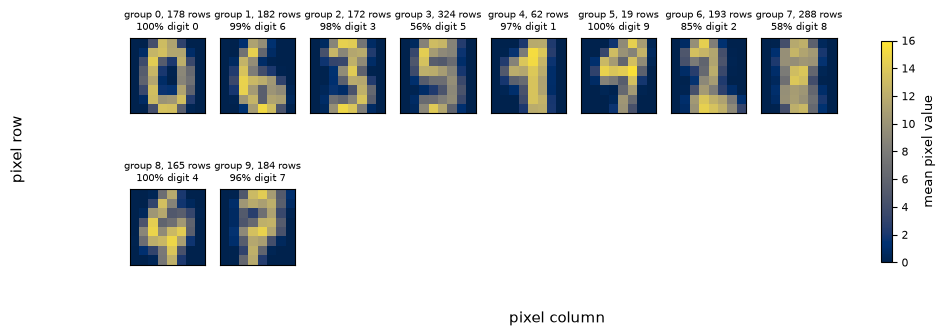

In [18]:
print(f"coverage-adjusted ARI, Starfold: {coverage_adjusted_ari(truth, labels):.3f}")
print(f"coverage-adjusted ARI, defaults: {coverage_adjusted_ari(truth, result.default_labels):.3f}")

ncols = min(8, max(groups.size, 1))
nrows = max(1, -(-groups.size // ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(1.3 * ncols + 1, 1.5 * nrows + 0.6), squeeze=False)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_visible(False)
image = None
for ax, group, majority, part in zip(axes.flat, groups, digit, share, strict=False):
    ax.set_visible(True)
    image = ax.imshow(
        x[labels == group].mean(axis=0).reshape(8, 8), cmap="cividis", vmin=0, vmax=16
    )
    ax.set_title(f"group {group}, {sizes[group]} rows\n{part:.0%} digit {majority}", fontsize=7)
if image is not None:
    fig.colorbar(image, ax=axes, label="mean pixel value", shrink=0.8)
fig.supxlabel("pixel column")
fig.supylabel("pixel row")
plt.show()

In the stored run Starfold scores 0.740 and the defaults
0.594. Eight of the ten mean images show a clear digit, with a majority share
of 85 percent or more. Groups 3 and 7, the two largest, are mixed: 56 percent
digit 5 and 58 percent digit 8. Group 3 also had one of the lowest
recurrences (0.54). Low recurrence warned about group 3 before the labels
were used; group 7 shows that a group can recur fairly well and still mix two
digits.

## Save and reload

Save the result so that you, or anyone else, can reload it later without
running the search again. `starfold.save` writes a folder with three files:

- `result.json`: the settings, scores, flags and provenance (the versions, the
  configuration, the seed and the engine actually used);
- `arrays.npz`: the arrays such as `labels` and `support`. They are read back
  with `allow_pickle=False`, so the file cannot hold executable code;
- a manifest of SHA-256 checksums, fingerprints that change if any file is
  altered.

`starfold.load` checks the checksums and derives the flags again from the
arrays. The cell stops with an error if the reloaded labels or flags differ.
The run goes to `notebooks/runs/digits`, which git ignores. The manual's
[save and load page](https://andreaswneitzel.github.io/Starfold/howto/save-and-load.html)
has more.

In [19]:
path = starfold.save(result, RUN_DIR)
loaded = starfold.load(path)
if not (np.array_equal(loaded.labels, result.labels) and loaded.flags == result.flags):
    msg = "The reloaded result differs from the one in memory."
    raise RuntimeError(msg)
print(f"saved to {path}; labels and flags match after reloading")

saved to /home/aneitzel/projects/starfold/notebooks/runs/digits; labels and flags match after reloading


## Next

You have run Starfold once and read every part of its result. Two notebooks
continue from here:

- Notebook 02 runs Starfold on the APOGEE DR19 example table, a real
  table with no labels at all, where no post hoc check is possible.
- Notebook 03 runs the calibration test on the digits run saved above.

The manual's
[reporting page](https://andreaswneitzel.github.io/Starfold/howto/report-your-result.html)
lists what to write down from a run like this one.